##  Perform image classification using a pre-trained Vision Transformer (ViT) model and compare its performance with a CNN model. 




In [4]:
# 1. IMPORT LIBRARIES AND VERIFY GPU

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights, vit_b_16, ViT_B_16_Weights

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from pathlib import Path

from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score
)

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is NOT available. Check your PyTorch CUDA installation "
        "before training. This notebook requires GPU training."
    )

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA Version:", torch.version.cuda)

props = torch.cuda.get_device_properties(0)
print(f"GPU Memory: {props.total_memory / (1024**3):.2f} GB")

Path("results").mkdir(exist_ok=True)
print("\nGPU training is ENABLED.")


PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU: NVIDIA GeForce RTX 2050
CUDA Version: 13.0
GPU Memory: 4.00 GB

GPU training is ENABLED.


In [8]:
# 2. CIFAR-10 CLASSES

classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Number of classes:", len(classes))
print(classes)


Number of classes: 10
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [9]:
# 3. DATA PREPROCESSING

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [10]:
# 4. LOAD CIFAR-10

train_dataset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=train_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=test_transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))


Training images: 50000
Testing images: 10000


In [11]:
# 5. DATALOADERS

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Training batches: 782
Testing batches: 157


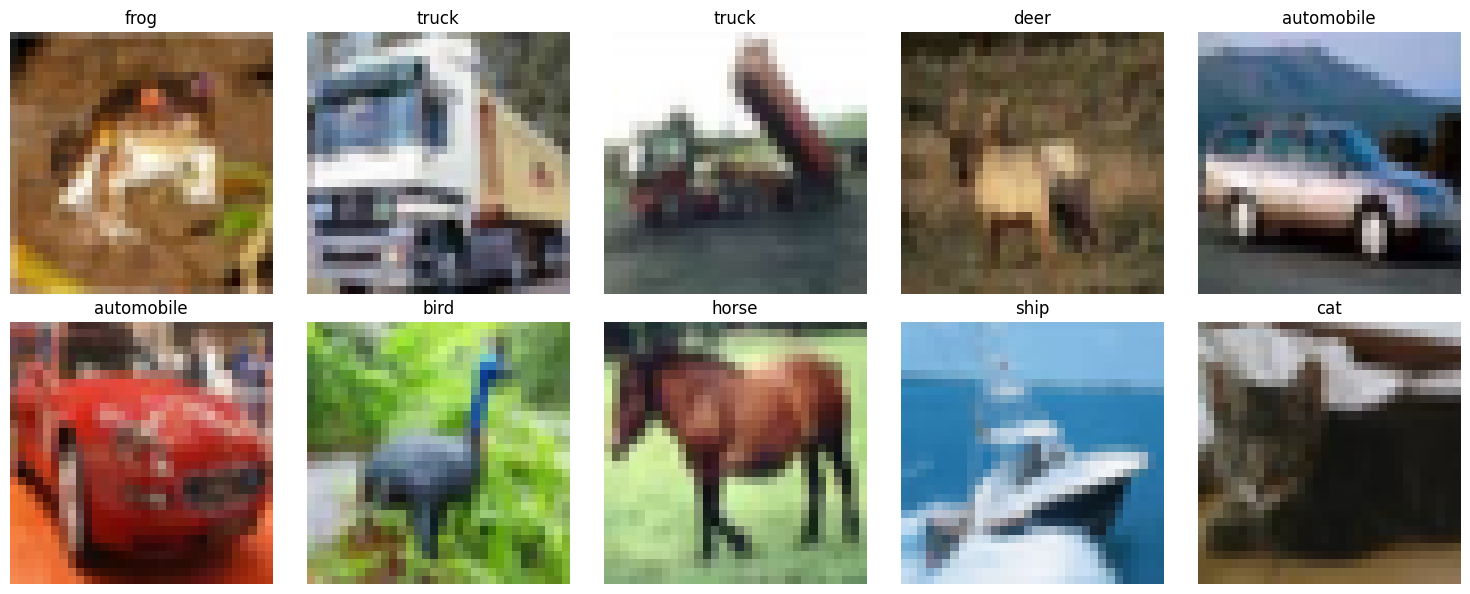

In [12]:
# 6. VISUALIZE SAMPLE IMAGES

visual_dataset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=False
)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):
    image, label = visual_dataset[i]
    ax.imshow(image)
    ax.set_title(classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()


# Part A — CNN using Pre-trained ResNet-18

In [8]:
# 7. LOAD PRETRAINED RESNET-18

cnn_model = resnet18(weights=ResNet18_Weights.DEFAULT)
cnn_model.fc = nn.Linear(cnn_model.fc.in_features, 10)
cnn_model = cnn_model.to(device)

print("CNN model device:", next(cnn_model.parameters()).device)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Samarth/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


CNN model device: cuda:0


In [9]:
# 8. CNN LOSS AND OPTIMIZER

cnn_criterion = nn.CrossEntropyLoss()
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.0001)

CNN_EPOCHS = 5


In [10]:
# 9. TRAIN CNN ON GPU

cnn_train_losses = []
cnn_train_accuracies = []

start_time = time.time()

for epoch in range(CNN_EPOCHS):
    cnn_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        cnn_optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = cnn_criterion(outputs, labels)
        loss.backward()
        cnn_optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    cnn_train_losses.append(epoch_loss)
    cnn_train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{CNN_EPOCHS}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

cnn_training_time = time.time() - start_time

print(f"\nCNN Training Time: {cnn_training_time/60:.2f} minutes")
print(f"GPU Memory Allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB")
print(f"GPU Memory Reserved: {torch.cuda.memory_reserved()/1024**3:.2f} GB")


Epoch [1/5] Loss: 0.3189 Accuracy: 89.62%
Epoch [2/5] Loss: 0.1422 Accuracy: 95.20%
Epoch [3/5] Loss: 0.0928 Accuracy: 96.91%
Epoch [4/5] Loss: 0.0680 Accuracy: 97.76%
Epoch [5/5] Loss: 0.0573 Accuracy: 98.05%

CNN Training Time: 20.36 minutes
GPU Memory Allocated: 0.19 GB
GPU Memory Reserved: 2.57 GB


In [11]:
# 10. GENERIC EVALUATION FUNCTION

def evaluate_model(model, loader, criterion):
    model.eval()
    all_predictions = []
    all_labels = []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

            _, predictions = torch.max(outputs, 1)
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(loader)
    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(all_labels, all_predictions, average="weighted", zero_division=0)
    recall = recall_score(all_labels, all_predictions, average="weighted", zero_division=0)
    f1 = f1_score(all_labels, all_predictions, average="weighted", zero_division=0)

    return avg_loss, accuracy, precision, recall, f1, all_labels, all_predictions


In [12]:
# 11. EVALUATE CNN

(
    cnn_loss, cnn_accuracy, cnn_precision, cnn_recall,
    cnn_f1, cnn_labels, cnn_predictions
) = evaluate_model(cnn_model, test_loader, cnn_criterion)

print("CNN Results")
print("-" * 30)
print(f"Loss      : {cnn_loss:.4f}")
print(f"Accuracy  : {cnn_accuracy*100:.2f}%")
print(f"Precision : {cnn_precision:.4f}")
print(f"Recall    : {cnn_recall:.4f}")
print(f"F1 Score  : {cnn_f1:.4f}")


CNN Results
------------------------------
Loss      : 0.1792
Accuracy  : 94.25%
Precision : 0.9427
Recall    : 0.9425
F1 Score  : 0.9422


              precision    recall  f1-score   support

    airplane       0.96      0.96      0.96      1000
  automobile       0.92      0.99      0.96      1000
        bird       0.94      0.94      0.94      1000
         cat       0.91      0.85      0.88      1000
        deer       0.93      0.96      0.94      1000
         dog       0.91      0.92      0.91      1000
        frog       0.96      0.97      0.96      1000
       horse       0.96      0.96      0.96      1000
        ship       0.96      0.97      0.97      1000
       truck       0.98      0.92      0.95      1000

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



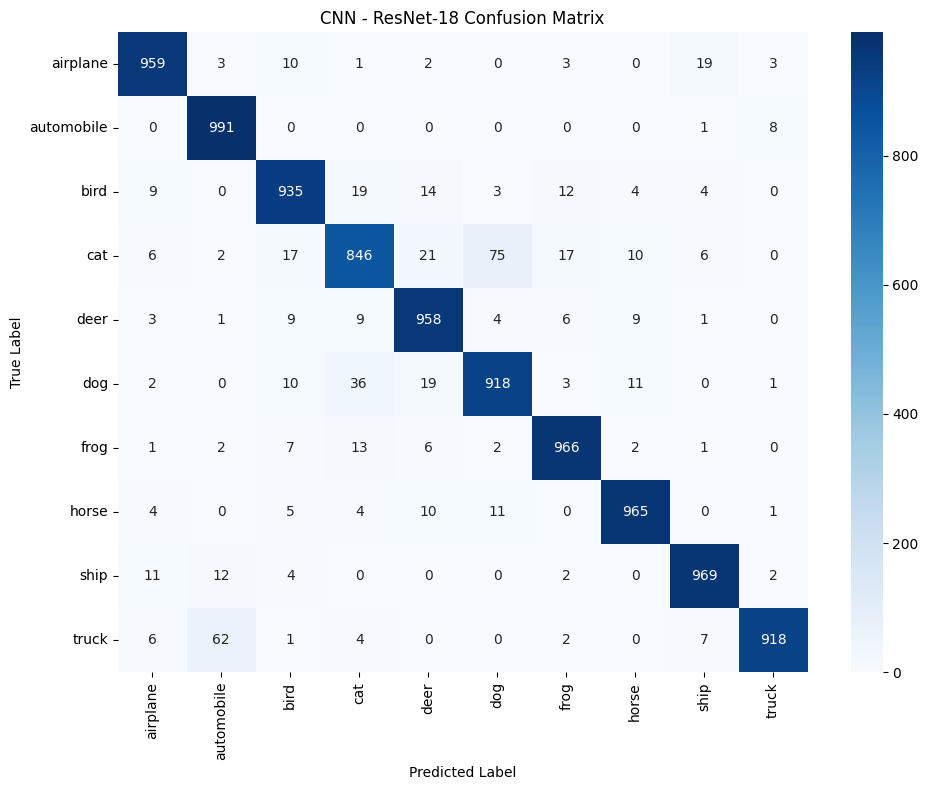

In [13]:
# 12. CNN REPORT AND CONFUSION MATRIX

print(classification_report(
    cnn_labels, cnn_predictions,
    target_names=classes, zero_division=0
))

cnn_cm = confusion_matrix(cnn_labels, cnn_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cnn_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=classes, yticklabels=classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN - ResNet-18 Confusion Matrix")
plt.tight_layout()
plt.savefig("results/cnn_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()


# Part B — Vision Transformer using Pre-trained ViT-B/16

In [1]:
# 13. LOAD PRETRAINED VIT-B/16

vit_model = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)
vit_model.heads.head = nn.Linear(vit_model.heads.head.in_features, 10)
vit_model = vit_model.to(device)

print("ViT model device:", next(vit_model.parameters()).device)


NameError: name 'vit_b_16' is not defined

In [6]:
# 14. VIT LOSS AND OPTIMIZER

vit_criterion = nn.CrossEntropyLoss()
vit_optimizer = optim.Adam(vit_model.parameters(), lr=0.0001)

VIT_EPOCHS = 5


In [ ]:
# 15. TRAIN VIT ON GPU

# Train only the classifier head; full ViT-B/16 fine-tuning is too costly on a 4 GB GPU.
for param in vit_model.parameters():
    param.requires_grad = False
for param in vit_model.heads.parameters():
    param.requires_grad = True

vit_optimizer = optim.Adam(
    (param for param in vit_model.parameters() if param.requires_grad), lr=0.0001
)
vit_train_losses = []
vit_train_accuracies = []
vit_scaler = torch.amp.GradScaler("cuda")

start_time = time.time()

for epoch in range(VIT_EPOCHS):
    vit_model.eval()
    vit_model.heads.train()
    running_loss = torch.zeros((), device=device)
    correct = torch.zeros((), device=device, dtype=torch.long)
    total = 0

    for batch_index, (images, labels) in enumerate(train_loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        vit_optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            outputs = vit_model(images)
            loss = vit_criterion(outputs, labels)

        vit_scaler.scale(loss).backward()
        vit_scaler.step(vit_optimizer)
        vit_scaler.update()

        running_loss += loss.detach()
        predicted = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predicted == labels).sum()

        if (batch_index + 1) % 100 == 0 or batch_index + 1 == len(train_loader):
            print(
                f"Epoch [{epoch+1}/{VIT_EPOCHS}] "
                f"Batch [{batch_index+1}/{len(train_loader)}] "
                f"Loss: {running_loss.item()/(batch_index+1):.4f}",
                flush=True
            )

    epoch_loss = (running_loss / len(train_loader)).item()
    epoch_accuracy = 100 * correct.item() / total

    vit_train_losses.append(epoch_loss)
    vit_train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{VIT_EPOCHS}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

vit_training_time = time.time() - start_time

print(f"\nViT Training Time: {vit_training_time/60:.2f} minutes")
print(f"GPU Memory Allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB")
print(f"GPU Memory Reserved: {torch.cuda.memory_reserved()/1024**3:.2f} GB")

KeyboardInterrupt: 

In [ ]:
# 16. EVALUATE VIT

(
    vit_loss, vit_accuracy, vit_precision, vit_recall,
    vit_f1, vit_labels, vit_predictions
) = evaluate_model(vit_model, test_loader, vit_criterion)

print("ViT Results")
print("-" * 30)
print(f"Loss      : {vit_loss:.4f}")
print(f"Accuracy  : {vit_accuracy*100:.2f}%")
print(f"Precision : {vit_precision:.4f}")
print(f"Recall    : {vit_recall:.4f}")
print(f"F1 Score  : {vit_f1:.4f}")


In [ ]:
# 17. VIT REPORT AND CONFUSION MATRIX

print(classification_report(
    vit_labels, vit_predictions,
    target_names=classes, zero_division=0
))

vit_cm = confusion_matrix(vit_labels, vit_predictions)

plt.figure(figsize=(10, 8))
sns.heatmap(
    vit_cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=classes, yticklabels=classes
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Vision Transformer - ViT-B/16 Confusion Matrix")
plt.tight_layout()
plt.savefig("results/vit_confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()


# Part C — CNN vs ViT Comparison

In [ ]:
# 18. COMPARISON TABLE

comparison_df = pd.DataFrame({
    "Model": ["CNN - ResNet-18", "ViT - ViT-B/16"],
    "Test Loss": [cnn_loss, vit_loss],
    "Accuracy (%)": [cnn_accuracy*100, vit_accuracy*100],
    "Precision": [cnn_precision, vit_precision],
    "Recall": [cnn_recall, vit_recall],
    "F1 Score": [cnn_f1, vit_f1],
    "Training Time (min)": [cnn_training_time/60, vit_training_time/60]
})

display(comparison_df)

comparison_df.to_csv("results/model_comparison.csv", index=False)


In [ ]:
# 19. ACCURACY COMPARISON

models = ["CNN\n(ResNet-18)", "ViT\n(ViT-B/16)"]
accuracies = [cnn_accuracy*100, vit_accuracy*100]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies)
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("CNN vs ViT Accuracy")

for i, value in enumerate(accuracies):
    plt.text(i, value + 0.2, f"{value:.2f}%", ha="center")

plt.ylim(max(0, min(accuracies)-5), 100)
plt.tight_layout()
plt.savefig("results/accuracy_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
# 20. TRAINING TIME COMPARISON

training_times = [cnn_training_time/60, vit_training_time/60]

plt.figure(figsize=(8, 5))
plt.bar(models, training_times)
plt.ylabel("Training Time (minutes)")
plt.xlabel("Model")
plt.title("CNN vs ViT Training Time")

for i, value in enumerate(training_times):
    plt.text(i, value, f"{value:.2f}", ha="center")

plt.tight_layout()
plt.savefig("results/training_time_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
# 21. TRAINING LOSS COMPARISON

plt.figure(figsize=(10, 6))
plt.plot(range(1, CNN_EPOCHS+1), cnn_train_losses, marker="o", label="CNN - ResNet-18")
plt.plot(range(1, VIT_EPOCHS+1), vit_train_losses, marker="o", label="ViT - ViT-B/16")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss: CNN vs Vision Transformer")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("results/training_loss_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
# 22. TRAINING ACCURACY COMPARISON

plt.figure(figsize=(10, 6))
plt.plot(range(1, CNN_EPOCHS+1), cnn_train_accuracies, marker="o", label="CNN - ResNet-18")
plt.plot(range(1, VIT_EPOCHS+1), vit_train_accuracies, marker="o", label="ViT - ViT-B/16")
plt.xlabel("Epoch")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy: CNN vs Vision Transformer")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("results/training_accuracy_comparison.png", dpi=200, bbox_inches="tight")
plt.show()


In [ ]:
# 23. FINAL ANALYSIS

print("=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)
print(f"CNN Accuracy : {cnn_accuracy*100:.2f}%")
print(f"ViT Accuracy : {vit_accuracy*100:.2f}%")
print()
print(f"CNN Training Time: {cnn_training_time/60:.2f} minutes")
print(f"ViT Training Time: {vit_training_time/60:.2f} minutes")
print()

if cnn_accuracy > vit_accuracy:
    print("CNN achieved higher test accuracy.")
elif vit_accuracy > cnn_accuracy:
    print("Vision Transformer achieved higher test accuracy.")
else:
    print("Both models achieved the same test accuracy.")

print("=" * 60)
